# DATA 266 HW4.a — BERT Fine-Tuning and vLLM Inference

Kavan Siddesh Kumar · SID4 9486

This notebook is the HW4.a baseline that HW4.5 builds on. It has two parts:

1. A BERT sentiment classifier on Twitter data (TweetEval sentiment). The text is tokenized with `BertTokenizer`, packed into `TensorDataset`s, fine-tuned with `BertForSequenceClassification`, then saved and reloaded for custom inference.
2. A serving benchmark for a different Hugging Face model (`Qwen/Qwen2.5-0.5B-Instruct`) using vLLM at batch sizes 1, 8 and 32, compared against a plain Hugging Face pipeline at batch size 1.

**Run modes.** `RUN_MODE = "smoke"` is a tiny CPU check of every step (a few dozen rows, 2 epochs, vLLM skipped). `RUN_MODE = "gpu"` is the real run on the lab RTX 4090. Smoke outputs go to `results/smoke/`, `figures/smoke/` and `checkpoints/smoke/` and are never used as final numbers. If `RUN_MODE` is not set in the shell, the notebook picks `"gpu"` when a CUDA GPU is visible and `"smoke"` otherwise, so "Run All" in VS Code or Jupyter on the lab machine does the real run.

HW4.5 reads the config, split and baseline numbers this notebook saves, so this notebook has to be run first in the same mode.

In [1]:
%pip install -U pandas numpy matplotlib datasets transformers scikit-learn vllm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.0/125.0 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 5.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 8.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.0/133.0 kB 13.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.6/111.6 kB 11.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 10.3 MB/s eta 0:00:00
INFO: pip is looking at multiple ver

In [2]:
%conda install -y -c conda-forge compilers


| / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / 

In [3]:
import os
os.environ["VLLM_ENABLE_V1_MULTIPROCESSING"] = "0"
os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"
from vllm import LLM, SamplingParams
llm = LLM("Qwen/Qwen2.5-0.5B-Instruct", dtype="bfloat16", gpu_memory_utilization=0.5)
print(llm.generate(["Hello"], SamplingParams(temperature=0, max_tokens=8))[0].outputs[0].text)

(MainProcess pid=326) INFO 10-28 00:55:50 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'gpu_memory_utilization': 0.5, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=326) WARNING 10-28 00:55:50 [arg_utils.py:1910] The global random seed is set to 0. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=326) INFO 10-28 00:55:50 [model.py:699] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=326) INFO 10-28 00:55:50 [model.py:2109] Using max model len 32768
(MainProcess pid=326) INFO 10-28 00:55:50 [kernel.py:408] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=326) INFO 10-28 00:55:51 [core.py:129] Initializing a V1 LLM engine (v0.31.0) with config: model='Qwen/Qwen2.5-0.5B-Instruct', speculative_config=Non

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.77it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.76it/s]


(MainProcess pid=326) INFO 10-28 00:55:53 [default_loader.py:484] Loading weights took 0.27 seconds


(MainProcess pid=326) INFO 10-28 00:55:54 [model_runner.py:407] Model loading took 0.92 GiB memory and 2.266407 seconds
(MainProcess pid=326) INFO 10-28 00:55:57 [backends.py:1151] Dynamo bytecode transform time: 2.39 s
(MainProcess pid=326) INFO 10-28 00:56:02 [backends.py:391] Compiling a graph for compile range (1, 8192) takes 4.55 s
(MainProcess pid=326) INFO 10-28 00:56:03 [backends.py:916] collected artifacts: 25 entries, 3 artifacts, 4986543 bytes total
(MainProcess pid=326) INFO 10-28 00:56:03 [decorators.py:717] saved AOT compiled function to /root/.cache/vllm/torch_compile_cache/torch_aot_compile/9af4f5df6e06e772b8c1fe4d8f16b0a8da84d4716c7e499738a39dc2b6b3e146/rank_0_0/model
(MainProcess pid=326) INFO 10-28 00:56:03 [monitor.py:53] torch.compile took 8.54 s in total
(MainProcess pid=326) INFO 10-28 00:56:04 [monitor.py:81] Initial profiling/warmup run took 0.12 s


Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 37.98it/s]


(MainProcess pid=326) INFO 10-28 00:56:09 [model_runner.py:1087] Graph capturing finished in 3 secs, took 0.26 GiB
(MainProcess pid=326) INFO 10-28 00:56:10 [gpu_worker.py:692] Available KV cache memory: 10.22 GiB
(MainProcess pid=326) INFO 10-28 00:56:10 [gpu_worker.py:707] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.5000 is equivalent to --gpu-memory-utilization=0.4879 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.5121. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(MainProcess pid=326) INFO 10-28 00:56:10 [kv_cache_utils.py:2464] GPU KV cache size: 892,736 tokens, Maximum concurrency for 32,768 tokens per request: 27.24x
(MainProcess pid=326) INFO 10-28 00:56:10 [kernel_warmup.py:172] JIT kernel warmup starting.
(MainProcess pid=326) INFO 10-28 00:56:10 [kernel_warmup.py:185] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:00<00:00, 51.20it/s]


(MainProcess pid=326) INFO 10-28 00:56:26 [model_runner.py:1087] Graph capturing finished in 4 secs, took 0.18 GiB
(MainProcess pid=326) INFO 10-28 00:56:26 [gpu_worker.py:892] CUDA graph pool memory: 0.18 GiB (actual), 0.29 GiB (estimated), difference: 0.11 GiB (58.5%).
(MainProcess pid=326) INFO 10-28 00:56:26 [gpu_worker.py:955] Free memory on device (21.2/23.99 GiB) on startup. Desired GPU memory utilization is (0.5, 11.99 GiB). Actual usage is 1.17 GiB for consumed memory (weights + non-torch), 0.6 GiB for peak activation, and 0.18 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=10615647744` (9.89 GiB) to fit into requested memory, or `--kv-cache-memory=20495592960` (19.09 GiB) to fully utilize gpu memory. Current kv cache memory in use is 10.22 GiB.
(MainProcess pid=326) INFO 10-28 00:56:26 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(MainProcess pid=326) INFO 10-28 00:56

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  7.80it/s, est. speed input: 7.87 toks/s, output: 62.94 toks/s]



I am trying to create a program


## 2. Personal parameters and reproducibility

In [4]:
SID4 = 9486
SEED = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0

import os, torch
# "smoke" = local CPU check, "gpu" = RTX 4090 run. If RUN_MODE is not set in the shell
# (e.g. "Run All" in VS Code or Jupyter), it is "gpu" when a CUDA GPU is visible, else "smoke".
RUN_MODE = os.environ.get("RUN_MODE") or ("gpu" if torch.cuda.is_available() else "smoke")
assert RUN_MODE in ("smoke", "gpu"), RUN_MODE
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B} RUN_MODE={RUN_MODE}")

SID4=9486 SEED=9486 SLICE=486 HP_ID=0 CLS_A=6 CLS_B=0 RUN_MODE=gpu


In [5]:
# Must be set before CUDA is initialised for deterministic cuBLAS
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import random
import numpy as np
import torch

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
# warn_only: a few CUDA kernels have no deterministic version; PyTorch warns instead of failing
torch.use_deterministic_algorithms(True, warn_only=True)

SEED is used for Python, NumPy and PyTorch, for the train/validation/test split, for the training data order, and right before BERT is loaded so the new classifier head always starts from the same weights. Deterministic algorithms are switched on where PyTorch supports them. Remaining nondeterminism: some GPU kernels have no deterministic version, and vLLM manages its own CUDA kernels, so serving latencies vary a little from run to run.

## 3. Environment and hardware inspection

In [6]:
import sys, json, time, platform, subprocess, datetime, traceback, gc, hashlib
from importlib import metadata
from pathlib import Path

HW_DIR = Path.cwd()
RESULTS_DIR = HW_DIR / "results" / RUN_MODE
FIG_DIR = HW_DIR / "figures" / RUN_MODE
CKPT_DIR = HW_DIR / "checkpoints" / RUN_MODE
PROV_DIR = HW_DIR / "provenance"
for d in (RESULTS_DIR, FIG_DIR, CKPT_DIR, PROV_DIR):
    d.mkdir(parents=True, exist_ok=True)

CUDA = torch.cuda.is_available()
if RUN_MODE == "gpu" and not CUDA:
    raise RuntimeError("RUN_MODE is 'gpu' but torch.cuda.is_available() is False.")
DEVICE = torch.device("cuda" if CUDA else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if CUDA else "none (CPU only)"
if RUN_MODE == "smoke":
    RUN_LABEL = "[SMOKE TEST]"
elif "4090" in GPU_NAME:
    RUN_LABEL = "[RTX 4090 RUN]"
else:
    RUN_LABEL = f"[GPU RUN — {GPU_NAME}]"

LOG_FILE = RESULTS_DIR / "run_log_hw4a.txt"

def now_utc():
    return datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

def log(msg):
    line = f"{now_utc()} {RUN_LABEL} {msg}"
    print(line)
    with open(LOG_FILE, "a") as f:
        f.write(line + "\n")

def log_error(context, exc):
    log(f"[ERROR] {context}: {type(exc).__name__}: {exc}")
    with open(LOG_FILE, "a") as f:
        f.write(traceback.format_exc() + "\n")

def pkg_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

def run_cmd(cmd):
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=60).stdout.strip()
    except (FileNotFoundError, subprocess.TimeoutExpired) as e:
        return f"unavailable ({type(e).__name__})"

ENV = {
    "notebook": "HW4a_BERT_vLLM.ipynb",
    "run_mode": RUN_MODE,
    "run_label": RUN_LABEL,
    "start_utc": now_utc(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torch_cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if CUDA else None,
    "transformers": pkg_version("transformers"),
    "datasets": pkg_version("datasets"),
    "vllm": pkg_version("vllm"),
    "gpu_count": torch.cuda.device_count(),
    "gpu_name": GPU_NAME,
    "gpu_vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2) if CUDA else None,
    "nvidia_smi_L": run_cmd(["nvidia-smi", "-L"]) if CUDA else "not run (no CUDA)",
}
if CUDA:
    stamp = ENV["start_utc"].replace(":", "")
    (PROV_DIR / f"nvidia_smi_q_hw4a_{stamp}.txt").write_text(run_cmd(["nvidia-smi", "-q"]))

with open(LOG_FILE, "a") as f:
    f.write("\n" + "=" * 70 + "\n")
log("HW4a notebook started")
for k, v in ENV.items():
    print(f"{k:>14}: {v}")
_ = (RESULTS_DIR / "env_hw4a.json").write_text(json.dumps(ENV, indent=2))

2026-10-28T00:57:46Z [RTX 4090 RUN] HW4a notebook started
      notebook: HW4a_BERT_vLLM.ipynb
      run_mode: gpu
     run_label: [RTX 4090 RUN]
     start_utc: 2026-10-28T00:57:46Z
        python: 3.10.13
      platform: Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.31
         torch: 2.13.0+cu130
    torch_cuda: 13.0
         cudnn: 92000
  transformers: 5.17.0
      datasets: 5.1.0
          vllm: 0.31.0
     gpu_count: 1
      gpu_name: NVIDIA GeForce RTX 4090
   gpu_vram_gb: 23.99
  nvidia_smi_L: GPU 0: NVIDIA GeForce RTX 4090 (UUID: GPU-5a5ec28e-51c2-7128-c85d-2e75b9b3cd39)


## 4. Imports and helper functions

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup,
                          AutoTokenizer, AutoModelForCausalLM, pipeline)
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

GB = 1024 ** 3   # memory is reported in GiB (1024^3 bytes), written as GB in the tables

def sync():
    if CUDA:
        torch.cuda.synchronize()

def reset_peak():
    if CUDA:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

def peak_memory_gb():
    if CUDA:
        return torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
    return float("nan"), float("nan")

def free_memory():
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()

def md_table(frame, floatfmt="{:.3f}"):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    for _, r in frame.iterrows():
        lines.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

## 5. Configuration

Everything that defines the experiment is set here. The BERT settings follow the usual recommendations for fine-tuning BERT on a small classification set (learning rate 2e-5, batch size 32, a few epochs, linear decay, gradient clipping at 1.0). Training is plain FP32 on purpose, because HW4.5 compares memory techniques like mixed precision against this baseline.

For serving I picked `Qwen/Qwen2.5-0.5B-Instruct` as the "different model from the Hugging Face Hub". It's small enough to leave plenty of room on a 24 GB card and it's supported by vLLM. Each request generates exactly `MAX_NEW_TOKENS` tokens (greedy decoding, EOS ignored), so HF and vLLM produce the same number of tokens and tokens/s can be compared directly.

In [8]:
# Data
DATASET_NAME = "cardiffnlp/tweet_eval"
DATASET_CONFIG = "sentiment"
DATASET_SPLIT = "train"
DATASET_REVISION = "b3a375baf0f409c77e6bc7aa35102b7b3534f8be"   # pinned so HW4.5 sees the same rows
MAX_ROWS = 5000
LABEL_NAMES = ["negative", "neutral", "positive"]

# BERT fine-tune (the HW4 baseline settings)
BERT_MODEL = "google-bert/bert-base-uncased"
BERT_REVISION = "86b5e0934494bd15c9632b12f734a8a67f723594"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 4
LR = 2e-5
ADAM_EPS = 1e-8
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 0
GRAD_CLIP = 1.0
PRECISION = "fp32"
SMOKE_N = None

# Serving benchmark
SERVE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
SERVE_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
SERVE_DTYPE = "bfloat16"
MAX_NEW_TOKENS = 64
NUM_PROMPTS = 128
SERVE_BATCH_SIZES = [1, 8, 32]
WARMUP_CALLS = 2        # untimed calls per configuration before timing starts
TIMED_REPEATS = 2       # timed passes over the full prompt set
VLLM_GPU_MEM_UTIL = 0.85
PROMPT_TEMPLATE = 'Here is a tweet: "{tweet}"\nIn one sentence, explain what the writer is feeling and why.'

if RUN_MODE == "smoke":
    # [SMOKE TEST] tiny settings, only to check that every step runs
    SMOKE_N = {"train": 48, "val": 16, "test": 24}
    EPOCHS = 2
    BATCH_SIZE = 16
    SERVE_DTYPE = "float32"   # bf16 matmuls are slow on CPU
    NUM_PROMPTS = 2
    MAX_NEW_TOKENS = 8
    WARMUP_CALLS = 1
    TIMED_REPEATS = 1

CONFIG = {
    "run_mode": RUN_MODE, "seed": SEED, "slice": SLICE,
    "dataset_name": DATASET_NAME, "dataset_config": DATASET_CONFIG, "dataset_split": DATASET_SPLIT,
    "dataset_revision": DATASET_REVISION, "max_rows": MAX_ROWS, "label_names": LABEL_NAMES,
    "bert_model": BERT_MODEL, "bert_revision": BERT_REVISION, "max_len": MAX_LEN, "batch_size": BATCH_SIZE,
    "epochs": EPOCHS, "lr": LR, "adam_eps": ADAM_EPS, "weight_decay": WEIGHT_DECAY,
    "warmup_steps": WARMUP_STEPS, "grad_clip": GRAD_CLIP, "precision": PRECISION, "smoke_n": SMOKE_N,
    "serve_model": SERVE_MODEL, "serve_revision": SERVE_REVISION, "serve_dtype": SERVE_DTYPE,
    "max_new_tokens": MAX_NEW_TOKENS, "num_prompts": NUM_PROMPTS, "serve_batch_sizes": SERVE_BATCH_SIZES,
    "warmup_calls": WARMUP_CALLS, "timed_repeats": TIMED_REPEATS, "vllm_gpu_mem_util": VLLM_GPU_MEM_UTIL,
    "prompt_template": PROMPT_TEMPLATE,
}
(RESULTS_DIR / "hw4a_config.json").write_text(json.dumps(CONFIG, indent=2))
for k, v in CONFIG.items():
    print(f"{k:>18}: {v}")

          run_mode: gpu
              seed: 9486
             slice: 486
      dataset_name: cardiffnlp/tweet_eval
    dataset_config: sentiment
     dataset_split: train
  dataset_revision: b3a375baf0f409c77e6bc7aa35102b7b3534f8be
          max_rows: 5000
       label_names: ['negative', 'neutral', 'positive']
        bert_model: google-bert/bert-base-uncased
     bert_revision: 86b5e0934494bd15c9632b12f734a8a67f723594
           max_len: 128
        batch_size: 32
            epochs: 4
                lr: 2e-05
          adam_eps: 1e-08
      weight_decay: 0.01
      warmup_steps: 0
         grad_clip: 1.0
         precision: fp32
           smoke_n: None
       serve_model: Qwen/Qwen2.5-0.5B-Instruct
    serve_revision: 7ae557604adf67be50417f59c2c2f167def9a775
       serve_dtype: bfloat16
    max_new_tokens: 64
       num_prompts: 128
 serve_batch_sizes: [1, 8, 32]
      warmup_calls: 2
     timed_repeats: 2
 vllm_gpu_mem_util: 0.85
   prompt_template: Here is a tweet: "{tweet}"
In 

## 6. Data loading and exact row range

TweetEval sentiment has three classes (0 negative, 1 neutral, 2 positive). I take up to 5,000 consecutive rows of the train split starting at SLICE = 486. Download time isn't part of any timing. A SHA-256 hash of the selected rows is saved so HW4.5 can check it is using exactly the same data.

In [9]:
raw = load_dataset(DATASET_NAME, DATASET_CONFIG, split=DATASET_SPLIT, revision=DATASET_REVISION)
assert raw.features["label"].names == LABEL_NAMES, raw.features["label"].names
N_AVAILABLE = len(raw)
ROW_START = SLICE
ROW_END = min(SLICE + MAX_ROWS, N_AVAILABLE)   # exclusive
subset = raw.select(range(ROW_START, ROW_END))
df = pd.DataFrame({"row_id": np.arange(ROW_START, ROW_END), "text": subset["text"], "label": subset["label"]})
DATA_SHA256 = hashlib.sha256(
    "\n".join(f"{r}\t{l}\t{t}" for r, l, t in zip(df.row_id, df.label, df.text)).encode()).hexdigest()

log(f"Dataset {DATASET_NAME}/{DATASET_CONFIG} split={DATASET_SPLIT} revision={DATASET_REVISION[:12]}: "
    f"{N_AVAILABLE} rows available")
log(f"Rows used: {ROW_START} to {ROW_END - 1} inclusive ({len(df)} rows), sha256={DATA_SHA256[:16]}")
dist = df.label.value_counts().sort_index()
print(pd.DataFrame({"label": LABEL_NAMES, "count": dist.values, "percent": (100 * dist / len(df)).round(1).values}))
df.head()

Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 884687.62 examples/s]

2026-10-28T00:57:52Z [RTX 4090 RUN] Dataset cardiffnlp/tweet_eval/sentiment split=train revision=b3a375baf0f4: 45615 rows available
2026-10-28T00:57:52Z [RTX 4090 RUN] Rows used: 486 to 5485 inclusive (5000 rows), sha256=24886c35fad68ff9
      label  count  percent
0  negative    772     15.4
1   neutral   2288     45.8
2  positive   1940     38.8


,row_id,text,label
0,486,Raven-Symone -- Kim &amp; Kanye Sorta Came To ...,1
1,487,"""Yes, Sharknado 4 Is Happening: Sharknado 3 ha...",2
2,488,"""I don't see Islam on the march or people coun...",1
3,489,Our Eid offer ends tomorrow. Have you booked y...,1
4,490,"""RT @user Tiger Woods' former caddie Steve Wil...",1


## 7. Train / validation / test split and tokenizer

70 / 15 / 15 split with SEED. I stratify by label so the smaller negative class shows up in the same proportion in all three parts. The row ids of each part are saved to `results/hw4a_split.json`, which is shared by both run modes. If the file already exists, the notebook checks that the new split is identical instead of overwriting it.

In [10]:
train_ids, temp_ids = train_test_split(df.row_id.values, test_size=0.30, random_state=SEED,
                                       stratify=df.label.values)
temp_labels = df.set_index("row_id").loc[temp_ids, "label"].values
val_ids, test_ids = train_test_split(temp_ids, test_size=0.50, random_state=SEED, stratify=temp_labels)
train_ids, val_ids, test_ids = (sorted(map(int, x)) for x in (train_ids, val_ids, test_ids))
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))
assert len(train_ids) + len(val_ids) + len(test_ids) == len(df)

SPLIT_FILE = HW_DIR / "results" / "hw4a_split.json"
split_record = {"dataset": f"{DATASET_NAME}/{DATASET_CONFIG}/{DATASET_SPLIT}", "revision": DATASET_REVISION,
                "row_start": ROW_START, "row_end_inclusive": ROW_END - 1, "n_rows": len(df),
                "data_sha256": DATA_SHA256, "seed": SEED, "stratified": True,
                "train_ids": train_ids, "val_ids": val_ids, "test_ids": test_ids}
if SPLIT_FILE.exists():
    saved = json.loads(SPLIT_FILE.read_text())
    assert saved == split_record, "Split differs from the saved hw4a_split.json — data or seed changed"
    log("Split matches the saved results/hw4a_split.json")
else:
    SPLIT_FILE.write_text(json.dumps(split_record))
    log("Saved split to results/hw4a_split.json")

FULL_TRAIN_IDS, FULL_VAL_IDS, FULL_TEST_IDS = train_ids, val_ids, test_ids
split_sizes = {"train": len(train_ids), "val": len(val_ids), "test": len(test_ids)}
log(f"Split sizes (full): {split_sizes}")
if SMOKE_N:
    train_ids, val_ids, test_ids = train_ids[:SMOKE_N["train"]], val_ids[:SMOKE_N["val"]], test_ids[:SMOKE_N["test"]]
    log(f"Smoke subset: using only the first {SMOKE_N} ids of each split")

by_id = df.set_index("row_id")
for name, ids in (("train", train_ids), ("val", val_ids), ("test", test_ids)):
    print(name, by_id.loc[ids, "label"].value_counts().sort_index().to_dict())

2026-10-28T00:57:52Z [RTX 4090 RUN] Split matches the saved results/hw4a_split.json
2026-10-28T00:57:52Z [RTX 4090 RUN] Split sizes (full): {'train': 3500, 'val': 750, 'test': 750}
train {0: 540, 1: 1602, 2: 1358}
val {0: 116, 1: 343, 2: 291}
test {0: 116, 1: 343, 2: 291}


In [11]:
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL, revision=BERT_REVISION)

full_lengths = [len(x) for x in tokenizer(df.text.tolist())["input_ids"]]
n_trunc = sum(l > MAX_LEN for l in full_lengths)
log(f"Token lengths with [CLS]/[SEP]: median {np.median(full_lengths):.0f}, max {max(full_lengths)}; "
    f"{n_trunc} of {len(full_lengths)} tweets longer than MAX_LEN={MAX_LEN}")

def encode(ids):
    part = by_id.loc[ids]
    enc = tokenizer(part.text.tolist(), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(part.label.values, dtype=torch.long))

train_ds, val_ds, test_ds = encode(train_ids), encode(val_ids), encode(test_ids)
for name, ds in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    print(name, [tuple(t.shape) for t in ds.tensors])
assert train_ds.tensors[0].shape == (len(train_ids), MAX_LEN)

train_loader = DataLoader(train_ds, sampler=RandomSampler(train_ds, generator=torch.Generator().manual_seed(SEED)),
                          batch_size=BATCH_SIZE)
val_loader = DataLoader(val_ds, sampler=SequentialSampler(val_ds), batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, sampler=SequentialSampler(test_ds), batch_size=BATCH_SIZE)
print("example:", tokenizer.convert_ids_to_tokens(train_ds.tensors[0][0][:20].tolist()))

2026-10-28T00:57:53Z [RTX 4090 RUN] Token lengths with [CLS]/[SEP]: median 30, max 89; 0 of 5000 tweets longer than MAX_LEN=128
train [(3500, 128), (3500, 128), (3500,)]
val [(750, 128), (750, 128), (750,)]
test [(750, 128), (750, 128), (750,)]
example: ['[CLS]', 'raven', '-', 'sy', '##mon', '##e', '-', '-', 'kim', '&', 'amp', ';', 'kanye', 'sort', '##a', 'came', 'to', 'my', '30th', '(']


## 8. Model setup and shape check

In [12]:
set_seed(SEED)   # fixes the random init of the new classification head
model = BertForSequenceClassification.from_pretrained(
    BERT_MODEL, revision=BERT_REVISION, num_labels=len(LABEL_NAMES),
    id2label=dict(enumerate(LABEL_NAMES)), label2id={n: i for i, n in enumerate(LABEL_NAMES)}).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
log(f"Loaded {BERT_MODEL} with {n_params:,} parameters on {DEVICE}")

# shape check on a validation batch (the train loader is not touched so the training order stays the same)
model.eval()
ids, mask, y = (t.to(DEVICE) for t in next(iter(val_loader)))
with torch.no_grad():
    logits = model(input_ids=ids, attention_mask=mask).logits
print("input_ids", tuple(ids.shape), "attention_mask", tuple(mask.shape), "labels", tuple(y.shape), "logits", tuple(logits.shape))
assert logits.shape == (ids.shape[0], len(LABEL_NAMES))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1876.95it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

2026-10-28T00:58:04Z [RTX 4090 RUN] Loaded google-bert/bert-base-uncased with 109,484,547 parameters on cuda
input_ids (32, 128) attention_mask (32, 128) labels (32,) logits (32, 3)


## 9. Fine-tuning

Standard loop: AdamW, a linear learning-rate decay, gradient clipping, then validation after every epoch. Training time is measured with `time.perf_counter()` and `torch.cuda.synchronize()` and only covers the training steps; validation time is recorded separately. Peak GPU memory is reset right before training starts, so it covers the whole fine-tune including validation. The weights from the epoch with the lowest validation loss are kept for testing.

In [13]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=WARMUP_STEPS, num_training_steps=total_steps)

def evaluate(model, loader):
    model.eval()
    total_loss, preds, labels, probs = 0.0, [], [], []
    with torch.no_grad():
        for ids, mask, y in loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            out = model(input_ids=ids, attention_mask=mask, labels=y)
            total_loss += out.loss.item() * len(y)
            p = torch.softmax(out.logits.float(), dim=-1)
            probs.append(p.cpu()); preds.append(p.argmax(-1).cpu()); labels.append(y.cpu())
    preds, labels, probs = torch.cat(preds).numpy(), torch.cat(labels).numpy(), torch.cat(probs).numpy()
    return total_loss / len(labels), accuracy_score(labels, preds), preds, labels, probs

history = []
best = {"val_loss": float("inf"), "epoch": None, "state": None}
free_memory()
reset_peak()
run_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n_seen = 0.0, 0
    sync(); t0 = time.perf_counter()
    for ids, mask, y in train_loader:
        ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        out = model(input_ids=ids, attention_mask=mask, labels=y)
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running += out.loss.item() * len(y)
        n_seen += len(y)
    sync(); epoch_train_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    val_loss, val_acc, _, _, _ = evaluate(model, val_loader)
    sync(); val_s = time.perf_counter() - t1
    history.append({"epoch": epoch, "train_loss": running / n_seen, "val_loss": val_loss, "val_acc": val_acc,
                    "epoch_train_s": epoch_train_s, "val_eval_s": val_s, "train_samples_per_s": n_seen / epoch_train_s})
    log(f"epoch {epoch}: train_loss {running / n_seen:.4f}  val_loss {val_loss:.4f}  val_acc {val_acc:.4f}  "
        f"train {epoch_train_s:.1f}s  val {val_s:.1f}s")
    if val_loss < best["val_loss"]:
        best = {"val_loss": val_loss, "epoch": epoch,
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
sync()
total_wall_s = time.perf_counter() - run_start
peak_alloc_gb, peak_reserved_gb = peak_memory_gb()
log(f"Training done: {sum(h['epoch_train_s'] for h in history):.1f}s training, {total_wall_s:.1f}s including validation, "
    f"peak allocated {peak_alloc_gb:.3f} GB, peak reserved {peak_reserved_gb:.3f} GB")

/opt/conda/lib/python3.10/site-packages/torch/autograd/graph.py:979: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:833.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


2026-10-28T00:58:14Z [RTX 4090 RUN] epoch 1: train_loss 0.9186  val_loss 0.7432  val_acc 0.6627  train 9.3s  val 0.6s
2026-10-28T00:58:24Z [RTX 4090 RUN] epoch 2: train_loss 0.6728  val_loss 0.6893  val_acc 0.6893  train 8.9s  val 0.6s
2026-10-28T00:58:34Z [RTX 4090 RUN] epoch 3: train_loss 0.4994  val_loss 0.7027  val_acc 0.7107  train 9.0s  val 0.6s
2026-10-28T00:58:43Z [RTX 4090 RUN] epoch 4: train_loss 0.3888  val_loss 0.7234  val_acc 0.7120  train 9.0s  val 0.6s
2026-10-28T00:58:44Z [RTX 4090 RUN] Training done: 36.2s training, 39.8s including validation, peak allocated 16.273 GB, peak reserved 16.666 GB


## 10. Training curves and where validation stopped improving

 epoch  train_loss  val_loss  val_acc  epoch_train_s  val_eval_s  train_samples_per_s
     1      0.9186    0.7432   0.6627         9.2679      0.5626             377.6458
     2      0.6728    0.6893   0.6893         8.9350      0.5753             391.7201
     3      0.4994    0.7027   0.7107         9.0112      0.5656             388.4049
     4      0.3888    0.7234   0.7120         8.9565      0.5642             390.7782

Lowest validation loss at epoch 2; highest validation accuracy at epoch 4.
Training past epoch 2 cost 19.1s (2 extra epochs). Val loss went 0.6893 -> 0.7234, val acc 0.6893 -> 0.7120.


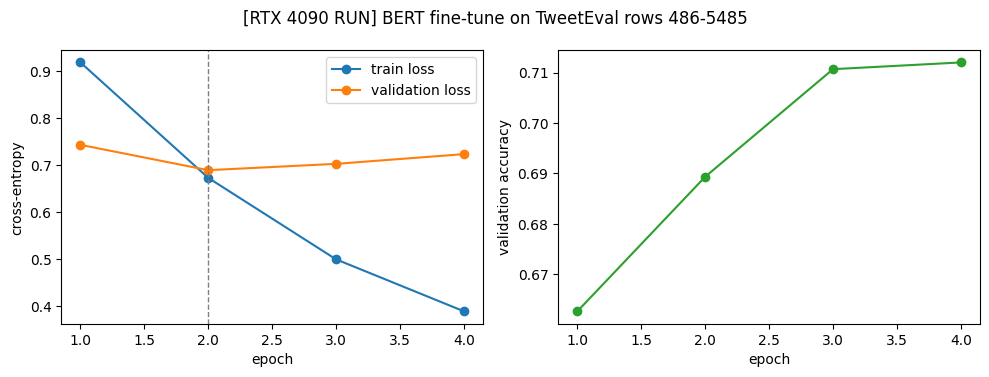

In [14]:
hist = pd.DataFrame(history)
hist.to_csv(RESULTS_DIR / "hw4a_epoch_history.csv", index=False)
best_loss_epoch = int(hist.loc[hist.val_loss.idxmin(), "epoch"])
best_acc_epoch = int(hist.loc[hist.val_acc.idxmax(), "epoch"])
after = hist[hist.epoch > best_loss_epoch]
extra_s = float(after.epoch_train_s.sum() + after.val_eval_s.sum())
print(hist.round(4).to_string(index=False))
print(f"\nLowest validation loss at epoch {best_loss_epoch}; highest validation accuracy at epoch {best_acc_epoch}.")
if len(after):
    last = hist.iloc[-1]
    print(f"Training past epoch {best_loss_epoch} cost {extra_s:.1f}s ({len(after)} extra epochs). "
          f"Val loss went {hist.val_loss.min():.4f} -> {last.val_loss:.4f}, val acc "
          f"{hist.loc[hist.epoch == best_loss_epoch, 'val_acc'].item():.4f} -> {last.val_acc:.4f}.")
else:
    print("Validation loss was still improving at the last epoch, so no epochs were wasted.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(hist.epoch, hist.train_loss, marker="o", label="train loss")
axes[0].plot(hist.epoch, hist.val_loss, marker="o", label="validation loss")
axes[0].axvline(best_loss_epoch, ls="--", c="gray", lw=1)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].legend()
axes[1].plot(hist.epoch, hist.val_acc, marker="o", c="tab:green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy")
fig.suptitle(f"{RUN_LABEL} BERT fine-tune on TweetEval rows {ROW_START}-{ROW_END - 1}")
fig.tight_layout()
fig.savefig(FIG_DIR / "training_curves.png", dpi=150)
plt.show()

## 11. Save the best checkpoint and reload it

The best-epoch weights are saved with `save_pretrained`, reloaded from disk, and checked to give the same logits as the in-memory model. The test evaluation and the custom inference below both use the reloaded model.

In [15]:
model.load_state_dict(best["state"])
BEST_DIR = CKPT_DIR / "hw4a_bert_best"
model.save_pretrained(BEST_DIR)
tokenizer.save_pretrained(BEST_DIR)
(BEST_DIR / "training_config.json").write_text(json.dumps(
    {**CONFIG, "best_epoch": best["epoch"], "split_sizes_used": {"train": len(train_ids), "val": len(val_ids), "test": len(test_ids)},
     "command": f"HW4a_BERT_vLLM.ipynb run top to bottom (Run All) with RUN_MODE={RUN_MODE}"}, indent=2))
log(f"Saved best checkpoint (epoch {best['epoch']}) to {BEST_DIR.relative_to(HW_DIR)}")

reloaded = BertForSequenceClassification.from_pretrained(BEST_DIR).to(DEVICE).eval()
model.eval()
ids, mask, _ = (t.to(DEVICE) for t in next(iter(val_loader)))
with torch.no_grad():
    diff = (model(input_ids=ids, attention_mask=mask).logits - reloaded(input_ids=ids, attention_mask=mask).logits).abs().max().item()
print(f"max |logit difference| between in-memory and reloaded model: {diff:.2e}")
assert diff < 1e-4

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.92s/it]


2026-10-28T00:58:47Z [RTX 4090 RUN] Saved best checkpoint (epoch 2) to checkpoints/gpu/hw4a_bert_best


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1301.62it/s]


max |logit difference| between in-memory and reloaded model: 0.00e+00


## 12. Test set: confusion matrix, per-class precision and recall, worst class

2026-10-28T00:58:50Z [RTX 4090 RUN] Test loss 0.6803, test accuracy 0.6840 on 750 rows; worst class by F1: negative
   class  precision  recall     f1  support
negative     0.5420  0.6121 0.5749      116
 neutral     0.7030  0.6764 0.6895      343
positive     0.7266  0.7216 0.7241      291


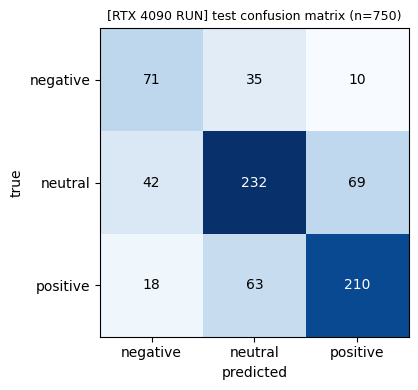

In [16]:
test_loss, test_acc, test_preds, test_labels, test_probs = evaluate(reloaded, test_loader)
assert len(test_preds) == len(test_labels) == len(test_ids)
cm = confusion_matrix(test_labels, test_preds, labels=list(range(len(LABEL_NAMES))))
assert cm.sum() == len(test_ids)
prec, rec, f1, sup = precision_recall_fscore_support(test_labels, test_preds, labels=list(range(len(LABEL_NAMES))), zero_division=0)
per_class = pd.DataFrame({"class": LABEL_NAMES, "precision": prec, "recall": rec, "f1": f1, "support": sup})
per_class.to_csv(RESULTS_DIR / "hw4a_per_class.csv", index=False)
pd.DataFrame(cm, index=[f"true_{n}" for n in LABEL_NAMES], columns=[f"pred_{n}" for n in LABEL_NAMES]).to_csv(RESULTS_DIR / "hw4a_confusion_matrix.csv")
WORST = int(np.argmin(f1))   # worst class = lowest F1, since F1 combines precision and recall
log(f"Test loss {test_loss:.4f}, test accuracy {test_acc:.4f} on {len(test_ids)} rows; worst class by F1: {LABEL_NAMES[WORST]}")
print(per_class.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(len(LABEL_NAMES)), LABEL_NAMES); ax.set_yticks(range(len(LABEL_NAMES)), LABEL_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"{RUN_LABEL} test confusion matrix (n={cm.sum()})", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [17]:
test_df = by_id.loc[test_ids].reset_index()
test_df["pred"] = test_preds
test_df["pred_prob"] = test_probs.max(axis=1)
mis = test_df[(test_df.label == WORST) & (test_df.pred != WORST)]
print(f"{len(mis)} misclassified test tweets whose true class is '{LABEL_NAMES[WORST]}'. First five:\n")
for _, r in mis.head(5).iterrows():
    print(f"row {r.row_id}: true={LABEL_NAMES[r.label]} pred={LABEL_NAMES[r.pred]} (p={r.pred_prob:.2f})\n   {r.text}\n")
mis.assign(true_name=mis.label.map(dict(enumerate(LABEL_NAMES))), pred_name=mis.pred.map(dict(enumerate(LABEL_NAMES)))) \
   .to_csv(RESULTS_DIR / "hw4a_worst_class_misclassified.csv", index=False)

45 misclassified test tweets whose true class is 'negative'. First five:

row 559: true=negative pred=neutral (p=0.53)
   BNP opposes Companies Act change: The BNP on Tuesday asked the government to drop the move to change Companies A...

row 904: true=negative pred=positive (p=0.71)
   it\u2019s a sunday\u002c i think in the spirit of douglas adams and feeling like shit i will have a second bath

row 953: true=negative pred=neutral (p=0.51)
   Amazon Prime is a lie. It said my stuff would be delivered by Monday. Its Wednesday, and still hasn't arrived. Tracking doesn't make sense.

row 1110: true=negative pred=neutral (p=0.77)
   Dr. going to see lot of people of stomach pain due to yakub's hanging tomorrow @user @user @user @user

row 1118: true=negative pred=neutral (p=0.69)
   @user @user That's Ashley in the 1st pic not Briana but the pregnancy is still fake af



**Diagnosis of the five misclassified examples** — pending the RTX 4090 run. I'll write a one-line diagnosis for each of the five tweets printed above once the final model exists, since the examples change with the trained weights.

| Row | True | Predicted | Diagnosis |
| --- | --- | --- | --- |
| pending | | | |

## 13. Custom inference with the reloaded model

In [18]:
MY_SENTENCES = [
    "I can't stop listening to the new album, it's on repeat all day!",
    "Stuck at the airport for five hours again. Great job, airline.",
    "The council meeting has been moved to 3pm on Thursday.",
]
enc = tokenizer(MY_SENTENCES, padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    p = torch.softmax(reloaded(**enc).logits.float(), dim=-1).cpu().numpy()
for s, row in zip(MY_SENTENCES, p):
    print(f"{LABEL_NAMES[row.argmax()]:>8} ({row.max():.2f})  {s}")

positive (0.70)  I can't stop listening to the new album, it's on repeat all day!
positive (0.90)  Stuck at the airport for five hours again. Great job, airline.
 neutral (0.83)  The council meeting has been moved to 3pm on Thursday.


## 14. Training memory and time record (baseline for HW4.5)

These are the HW4 fine-tune measurements HW4.5 compares against. They're the baseline for HW4.5 only, not for HW5.

In [19]:
HW4A_TRAINING = {
    "run_label": RUN_LABEL, "device": str(DEVICE), "gpu_name": GPU_NAME,
    "train_rows": len(train_ids), "val_rows": len(val_ids), "test_rows": len(test_ids),
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "steps_per_epoch": len(train_loader), "optimizer_steps": total_steps,
    "train_time_s": float(hist.epoch_train_s.sum()), "wall_time_incl_val_s": total_wall_s,
    "mean_epoch_train_s": float(hist.epoch_train_s.mean()),
    "train_samples_per_s": len(train_ids) * EPOCHS / float(hist.epoch_train_s.sum()),
    "peak_allocated_gb": peak_alloc_gb, "peak_reserved_gb": peak_reserved_gb,
    "best_epoch_val_loss": best_loss_epoch, "best_epoch_val_acc": best_acc_epoch,
    "test_loss": test_loss, "test_accuracy": test_acc, "worst_class": LABEL_NAMES[WORST],
}
(RESULTS_DIR / "hw4a_training.json").write_text(json.dumps(HW4A_TRAINING, indent=2))
for k, v in HW4A_TRAINING.items():
    print(f"{k:>22}: {v}")

del model, reloaded, optimizer, scheduler, best
free_memory()

             run_label: [RTX 4090 RUN]
                device: cuda
              gpu_name: NVIDIA GeForce RTX 4090
            train_rows: 3500
              val_rows: 750
             test_rows: 750
                epochs: 4
            batch_size: 32
       steps_per_epoch: 110
       optimizer_steps: 440
          train_time_s: 36.17059731299969
  wall_time_incl_val_s: 39.75996542100006
    mean_epoch_train_s: 9.042649328249922
   train_samples_per_s: 387.05470852062507
     peak_allocated_gb: 16.27327823638916
      peak_reserved_gb: 16.666015625
   best_epoch_val_loss: 2
    best_epoch_val_acc: 4
             test_loss: 0.680346601009369
         test_accuracy: 0.684
           worst_class: negative


## 15. Serving benchmark: HF pipeline vs vLLM

**Method.**
- **Prompts:** the first `NUM_PROMPTS` tweets of the test split, wrapped in my own prompt and the model's chat template. HF and vLLM get exactly the same prompt strings.
- **Generation:** greedy, exactly `MAX_NEW_TOKENS` new tokens per request (HF uses `min_new_tokens = max_new_tokens`, vLLM uses `ignore_eos=True`).
- **Warm-up and timing:** each configuration gets `WARMUP_CALLS` untimed calls first, then `TIMED_REPEATS` timed passes over the prompt set. Every timed call is wrapped in `torch.cuda.synchronize()` and `time.perf_counter()`. Model loading is never inside a timed region.
- **HF baseline:** a plain `pipeline("text-generation")` called one prompt at a time, so batch size 1 with no batching.
- **vLLM:** batching is supported directly. Each call passes a list of `batch_size` prompts to `LLM.generate`. vLLM's offline API returns the whole batch at once, so each request in a batch gets the batch's wall time as its latency.
- **Metrics:** tokens/s = total generated tokens ÷ total timed wall time. Requests/s is reported separately. p50 and p95 come from the individual request latencies.

In [20]:
serve_tok = AutoTokenizer.from_pretrained(SERVE_MODEL, revision=SERVE_REVISION)
prompt_row_ids = FULL_TEST_IDS[:NUM_PROMPTS]
PROMPTS = [serve_tok.apply_chat_template([{"role": "user", "content": PROMPT_TEMPLATE.format(tweet=by_id.loc[r, "text"])}],
                                         tokenize=False, add_generation_prompt=True) for r in prompt_row_ids]
prompt_lens = [len(serve_tok(p, add_special_tokens=False)["input_ids"]) for p in PROMPTS]
MAX_INPUT_TOKENS = max(prompt_lens)
(RESULTS_DIR / "hw4a_serving_prompts.json").write_text(json.dumps(
    {"template": PROMPT_TEMPLATE, "row_ids": prompt_row_ids, "prompts": PROMPTS, "prompt_tokens": prompt_lens}, indent=2))
log(f"{len(PROMPTS)} prompts, input tokens min {min(prompt_lens)} / median {int(np.median(prompt_lens))} / max {MAX_INPUT_TOKENS}")
print(PROMPTS[0])

serving_rows = []

def summarize_serving(rows):
    lat = np.array([r["latency_ms"] for r in rows])
    batch_walls = {(r["rep"], r["batch_index"]): r["batch_wall_ms"] for r in rows}
    total_s = sum(batch_walls.values()) / 1000
    tokens = sum(r["gen_tokens"] for r in rows)
    p50, p95 = float(np.percentile(lat, 50)), float(np.percentile(lat, 95))
    assert p50 <= p95
    return {"total_requests": len(rows), "total_generated_tokens": tokens, "timed_wall_s": total_s,
            "tokens_per_s": tokens / total_s, "requests_per_s": len(rows) / total_s, "p50_ms": p50, "p95_ms": p95}

2026-10-28T00:58:51Z [RTX 4090 RUN] 128 prompts, input tokens min 58 / median 76 / max 95
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Here is a tweet: "@user Well it rained all day on Eid, then second day was hot but then 3rd day and even aj bi its raining so""
In one sentence, explain what the writer is feeling and why.<|im_end|>
<|im_start|>assistant



In [22]:
SERVE_TORCH_DTYPE = getattr(torch, SERVE_DTYPE)
hf_model = AutoModelForCausalLM.from_pretrained(SERVE_MODEL, revision=SERVE_REVISION, dtype=SERVE_TORCH_DTYPE).to(DEVICE).eval()
hf_pipe = pipeline("text-generation", model=hf_model, tokenizer=serve_tok, device=DEVICE)
HF_GEN_KWARGS = dict(max_new_tokens=MAX_NEW_TOKENS, min_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                     temperature=None, top_p=None, top_k=None, return_full_text=False)

for w in range(WARMUP_CALLS):
    hf_pipe(PROMPTS[w % len(PROMPTS)], **HF_GEN_KWARGS)

reset_peak()
retok_counts = []
for rep in range(TIMED_REPEATS):
    for i, p in enumerate(PROMPTS):
        sync(); t0 = time.perf_counter()
        out = hf_pipe(p, **HF_GEN_KWARGS)
        sync(); ms = (time.perf_counter() - t0) * 1000
        retok_counts.append(len(serve_tok(out[0]["generated_text"], add_special_tokens=False)["input_ids"]))
        serving_rows.append({"config": "HF pipeline, batch 1", "engine": "hf_pipeline", "batch_size": 1, "rep": rep,
                             "batch_index": i, "request_index": i, "latency_ms": ms, "batch_wall_ms": ms,
                             "gen_tokens": MAX_NEW_TOKENS})
hf_peak = peak_memory_gb()
# generation is forced to exactly MAX_NEW_TOKENS; re-tokenizing the decoded text is only a sanity check
log(f"HF pipeline done. Re-tokenized output lengths: min {min(retok_counts)}, max {max(retok_counts)} "
    f"(expected about {MAX_NEW_TOKENS}); peak allocated {hf_peak[0]:.3f} GB")
print("sample output:", out[0]["generated_text"][:300])

del hf_pipe, hf_model
free_memory()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1970.84it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'do_sample', 'min_new_tokens', 'top_k', 'temperature', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=64) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


(MainProcess pid=326) WARNING 10-28 00:59:51 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _bmm_outer_product_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=64) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`

2026-10-28T01:05:07Z [RTX 4090 RUN] HF pipeline done. Re-tokenized output lengths: min 64, max 64 (expected about 64); peak allocated 14.347 GB
sample output: The writer is expressing excitement about their trip to London, particularly their use of a Merlin pass as a tourist identity, which they hope will provide them with a pleasant break. They appear to be sharing this information with @user for context or confirmation. The tone suggests a sense of anti


In [24]:
VLLM_STATUS = "not run"
VLLM_VERSION = pkg_version("vllm")
if not CUDA:
    VLLM_STATUS = "[SKIPPED IN SMOKE TEST] vLLM needs a CUDA GPU; it only runs with RUN_MODE='gpu' on the RTX 4090"
    log(VLLM_STATUS)
else:
    # Run the vLLM engine inside this kernel process: more reliable in Jupyter, and it means
    # torch.cuda.synchronize() here actually covers the engine's GPU work.
    os.environ["VLLM_ENABLE_V1_MULTIPROCESSING"] = "0"
    os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"
    torch.use_deterministic_algorithms(False)
    try:
        from vllm import LLM, SamplingParams
        llm = LLM(model=SERVE_MODEL, revision=SERVE_REVISION, dtype=SERVE_DTYPE,
                  gpu_memory_utilization=VLLM_GPU_MEM_UTIL, seed=SEED)
        sampling = SamplingParams(temperature=0.0, max_tokens=MAX_NEW_TOKENS, min_tokens=MAX_NEW_TOKENS, ignore_eos=True)
        for bs in SERVE_BATCH_SIZES:
            for _ in range(WARMUP_CALLS):
                llm.generate(PROMPTS[:bs], sampling, use_tqdm=False)
            for rep in range(TIMED_REPEATS):
                for b, start in enumerate(range(0, len(PROMPTS), bs)):
                    chunk = PROMPTS[start:start + bs]
                    sync(); t0 = time.perf_counter()
                    outs = llm.generate(chunk, sampling, use_tqdm=False)
                    sync(); ms = (time.perf_counter() - t0) * 1000
                    for j, o in enumerate(outs):
                        serving_rows.append({"config": f"vLLM, batch {bs}", "engine": "vllm", "batch_size": bs, "rep": rep,
                                             "batch_index": b, "request_index": start + j, "latency_ms": ms,
                                             "batch_wall_ms": ms, "gen_tokens": len(o.outputs[0].token_ids)})
            log(f"vLLM batch {bs} done")
        VLLM_STATUS = "completed"
        del llm
        free_memory()
    except Exception as e:
        VLLM_STATUS = f"[ERROR] {type(e).__name__}: {e}"
        log_error("vLLM benchmark", e)
print("vLLM version:", VLLM_VERSION, "| status:", VLLM_STATUS)

(MainProcess pid=326) INFO 10-28 01:05:10 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'seed': 9486, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=326) WARNING 10-28 01:05:10 [arg_utils.py:1910] The global random seed is set to 9486. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=326) INFO 10-28 01:05:10 [model.py:699] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=326) INFO 10-28 01:05:10 [model.py:2109] Using max model len 32768
(MainProcess pid=326) INFO 10-28 01:05:11 [kernel.py:408] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=326) INFO 10-28 01:05:13 [core.py:129] Initializing a V1 LLM engine (v0.31.

## 16. Serving results table and figures

Table HW4.1 — Serving comparison [RTX 4090 RUN] (vLLM status: [ERROR] ValueError: Free memory on device cuda:0 (9.28/23.99 GiB) on startup is less than desired GPU memory utilization (0.85, 20.39 GiB). Decrease GPU memory utilization or reduce GPU memory used by other processes.)

| config | tokens_per_s | p50_ms | p95_ms | requests_per_s | total_requests | total_generated_tokens |
| --- | --- | --- | --- | --- | --- | --- |
| HF pipeline, batch 1 | 52.3 | 1213.4 | 1339.6 | 0.8 | 256 | 16384 |


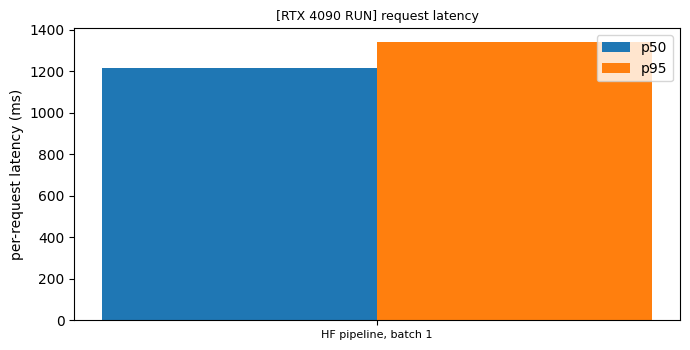

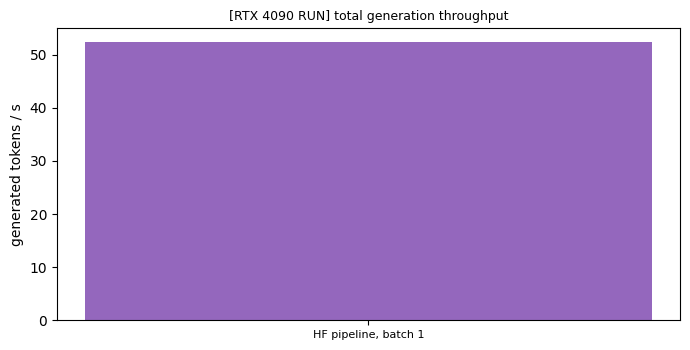

In [25]:
req = pd.DataFrame(serving_rows)
req.to_csv(RESULTS_DIR / "hw4a_serving_requests.csv", index=False)
summary = []
for cfg_name, g in req.groupby("config", sort=False):
    s = summarize_serving(g.to_dict("records"))
    engine = g.engine.iloc[0]
    summary.append({"config": cfg_name, "engine": engine, "batch_size": int(g.batch_size.iloc[0]), **s,
                    "batching": "none (one request per call)" if engine == "hf_pipeline" else "native (list of prompts to LLM.generate)",
                    "model": SERVE_MODEL, "dtype": SERVE_DTYPE, "max_input_tokens": MAX_INPUT_TOKENS,
                    "max_new_tokens": MAX_NEW_TOKENS, "warmup_calls": WARMUP_CALLS, "timed_repeats": TIMED_REPEATS,
                    "run_label": RUN_LABEL})
serve_summary = pd.DataFrame(summary)
serve_summary.to_csv(RESULTS_DIR / "hw4a_serving_summary.csv", index=False)
table = serve_summary[["config", "tokens_per_s", "p50_ms", "p95_ms", "requests_per_s", "total_requests", "total_generated_tokens"]]
print(f"Table HW4.1 — Serving comparison {RUN_LABEL} (vLLM status: {VLLM_STATUS})\n")
print(md_table(table, "{:.1f}"))
(RESULTS_DIR / "hw4a_tables.md").write_text(
    f"# HW4.a tables {RUN_LABEL}\n\n## Per-epoch history\n\n{md_table(hist, '{:.4f}')}\n\n"
    f"## Per-class test metrics\n\n{md_table(per_class, '{:.4f}')}\n\n## Table HW4.1 — Serving\n\n{md_table(table, '{:.1f}')}\n")

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(serve_summary))
ax.bar(x - 0.2, serve_summary.p50_ms, 0.4, label="p50")
ax.bar(x + 0.2, serve_summary.p95_ms, 0.4, label="p95")
ax.set_xticks(x, serve_summary.config, fontsize=8); ax.set_ylabel("per-request latency (ms)"); ax.legend()
ax.set_title(f"{RUN_LABEL} request latency", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "hw4a_serving_latency.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x, serve_summary.tokens_per_s, color="tab:purple")
ax.set_xticks(x, serve_summary.config, fontsize=8); ax.set_ylabel("generated tokens / s")
ax.set_title(f"{RUN_LABEL} total generation throughput", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "hw4a_serving_throughput.png", dpi=150); plt.show()

In [26]:
# Facts for the written answer below, computed from the summary table
hf = serve_summary[serve_summary.engine == "hf_pipeline"].iloc[0]
vl = serve_summary[serve_summary.engine == "vllm"].sort_values("batch_size")
if len(vl) == 0:
    print("No vLLM rows (", VLLM_STATUS, ") — nothing to compare yet.")
prev_tps = None
for _, r in vl.iterrows():
    worse = "worse" if r.p50_ms > hf.p50_ms else "better"
    gain = "" if prev_tps is None else f", throughput x{r.tokens_per_s / prev_tps:.2f} vs previous batch size"
    print(f"vLLM batch {r.batch_size}: p50 {r.p50_ms:.1f} ms ({worse} than HF p50 {hf.p50_ms:.1f} ms), "
          f"{r.tokens_per_s:.1f} tok/s{gain}")
    prev_tps = r.tokens_per_s

No vLLM rows ( [ERROR] ValueError: Free memory on device cuda:0 (9.28/23.99 GiB) on startup is less than desired GPU memory utilization (0.85, 20.39 GiB). Decrease GPU memory utilization or reduce GPU memory used by other processes. ) — nothing to compare yet.


## 17. Written answers

**Where validation stopped improving and the cost of training past it:** pending the RTX 4090 run (see the epoch table in section 10).

**Worst class:** pending the RTX 4090 run (see section 12).

**Serving question:** At which batch size does per-request latency become worse than the baseline while total throughput is still improving, and which of those two numbers matters for an interactive application? Pending the RTX 4090 run, to be answered from Table HW4.1 and the comparison printed above.

## 18. Reproducibility checklist

In [27]:
expected = [RESULTS_DIR / f for f in ("env_hw4a.json", "hw4a_config.json", "hw4a_epoch_history.csv", "hw4a_per_class.csv",
                                      "hw4a_confusion_matrix.csv", "hw4a_training.json", "hw4a_serving_prompts.json",
                                      "hw4a_serving_requests.csv", "hw4a_serving_summary.csv", "hw4a_tables.md")]
expected += [HW_DIR / "results" / "hw4a_split.json", BEST_DIR / "config.json",
             FIG_DIR / "training_curves.png", FIG_DIR / "confusion_matrix.png"]
for p in expected:
    print(("OK      " if p.exists() else "MISSING ") + str(p.relative_to(HW_DIR)))
assert all(p.exists() for p in expected)
print(f"Seeds set: SEED={SEED}; split saved and checked; dataset rows {ROW_START}-{ROW_END - 1}; vLLM: {VLLM_STATUS}")
ENV["end_utc"] = now_utc()
ENV["vllm_status"] = VLLM_STATUS
(RESULTS_DIR / "env_hw4a.json").write_text(json.dumps(ENV, indent=2))
log("HW4a notebook completed")

OK      results/gpu/env_hw4a.json
OK      results/gpu/hw4a_config.json
OK      results/gpu/hw4a_epoch_history.csv
OK      results/gpu/hw4a_per_class.csv
OK      results/gpu/hw4a_confusion_matrix.csv
OK      results/gpu/hw4a_training.json
OK      results/gpu/hw4a_serving_prompts.json
OK      results/gpu/hw4a_serving_requests.csv
OK      results/gpu/hw4a_serving_summary.csv
OK      results/gpu/hw4a_tables.md
OK      results/hw4a_split.json
OK      checkpoints/gpu/hw4a_bert_best/config.json
OK      figures/gpu/training_curves.png
OK      figures/gpu/confusion_matrix.png
Seeds set: SEED=9486; split saved and checked; dataset rows 486-5485; vLLM: [ERROR] ValueError: Free memory on device cuda:0 (9.28/23.99 GiB) on startup is less than desired GPU memory utilization (0.85, 20.39 GiB). Decrease GPU memory utilization or reduce GPU memory used by other processes.
2026-10-28T01:05:14Z [RTX 4090 RUN] HW4a notebook completed
